# 01 · Dataset EDA

**Goal:** check that the raw datasets are usable before feature extraction (notebook 02) and model training (03, 04).

**Datasets covered**
- StateFarm (distraction, side camera)
- NTHU-DDD (drowsiness, frames sorted into `drowsy` / `notdrowsy`)

**Note:** both sections reuse the variable `df`. The NTHU section (3) overwrites the StateFarm one (2).


In [ ]:
import pandas as pd
import numpy as np

## 1. Raw data inventory
Counts files, extensions and top-level subfolders for every dataset under `datasets/raw/`. Used to confirm each dataset is where the repo expects it.

In [2]:
from pathlib import Path
from collections import Counter

root = Path("D:/driver_monitoring_system/datasets/raw")
for ds in sorted(p for p in root.glob("*/*") if p.is_dir()):
    files = [f for f in ds.rglob("*") if f.is_file()]
    exts = Counter(f.suffix.lower() for f in files)
    subdirs = sorted(p.name for p in ds.iterdir() if p.is_dir())
    print(ds.relative_to(root), len(files), dict(exts.most_common(4)))
    print("   subfolders:", subdirs[:12])

distraction\head_train 1720 {'.jpg': 1720}
   subfolders: ['HEAD_TRAIN']
distraction\multiclass_dhaka 7276 {'.jpg': 7076, '.png': 200}
   subfolders: ['Multi-Class Driver Behavior Image Dataset']
distraction\statefarm 102153 {'.jpg': 102150, '.csv': 2, '.zip': 1}
   subfolders: ['state-farm-distracted-driver-detection']
drowsiness\eye_yawn_train 50542 {'.png': 45063, '.jpg': 5479}
   subfolders: ['EYE_TRAIN', 'YAWN_TRAIN']
drowsiness\kaggle_ddd 41793 {'.png': 41793}
   subfolders: ['Driver Drowsiness Dataset (DDD)']
drowsiness\nthu_ddd 18000 {'.jpg': 18000}
   subfolders: ['NTHU-DDD']
drowsiness\simuletic_synthetic 0 {}
   subfolders: []
drowsiness\yawdd 352 {'.avi': 349, '.pdf': 3}
   subfolders: ['YawDD dataset']


## 2. StateFarm (distraction)
Class counts, subject coverage and split design for the 10 distraction classes.

In [3]:
sf = root / "distraction" / "statefarm" / "state-farm-distracted-driver-detection"
df = pd.read_csv(next(sf.rglob("driver_imgs_list.csv")))
print(df.shape, df["subject"].nunique())
print(df["classname"].value_counts().sort_index())

(22424, 3) 26
classname
c0    2489
c1    2267
c2    2317
c3    2346
c4    2326
c5    2312
c6    2325
c7    2002
c8    1911
c9    2129
Name: count, dtype: int64


In [4]:
CLASS_NAMES = {
    "c0": "safe_driving",
    "c1": "texting_right",
    "c2": "phone_right",
    "c3": "texting_left",
    "c4": "phone_left",
    "c5": "operating_radio",
    "c6": "drinking",
    "c7": "reaching_behind",
    "c8": "hair_makeup",
    "c9": "talking_passenger",
}

df["label"] = df["classname"].map(CLASS_NAMES)
print(df["label"].value_counts())
assert df["label"].notna().all()   # fails loudly if any class code is unmapped

label
safe_driving         2489
texting_left         2346
phone_left           2326
drinking             2325
phone_right          2317
operating_radio      2312
texting_right        2267
talking_passenger    2129
reaching_behind      2002
hair_makeup          1911
Name: count, dtype: int64


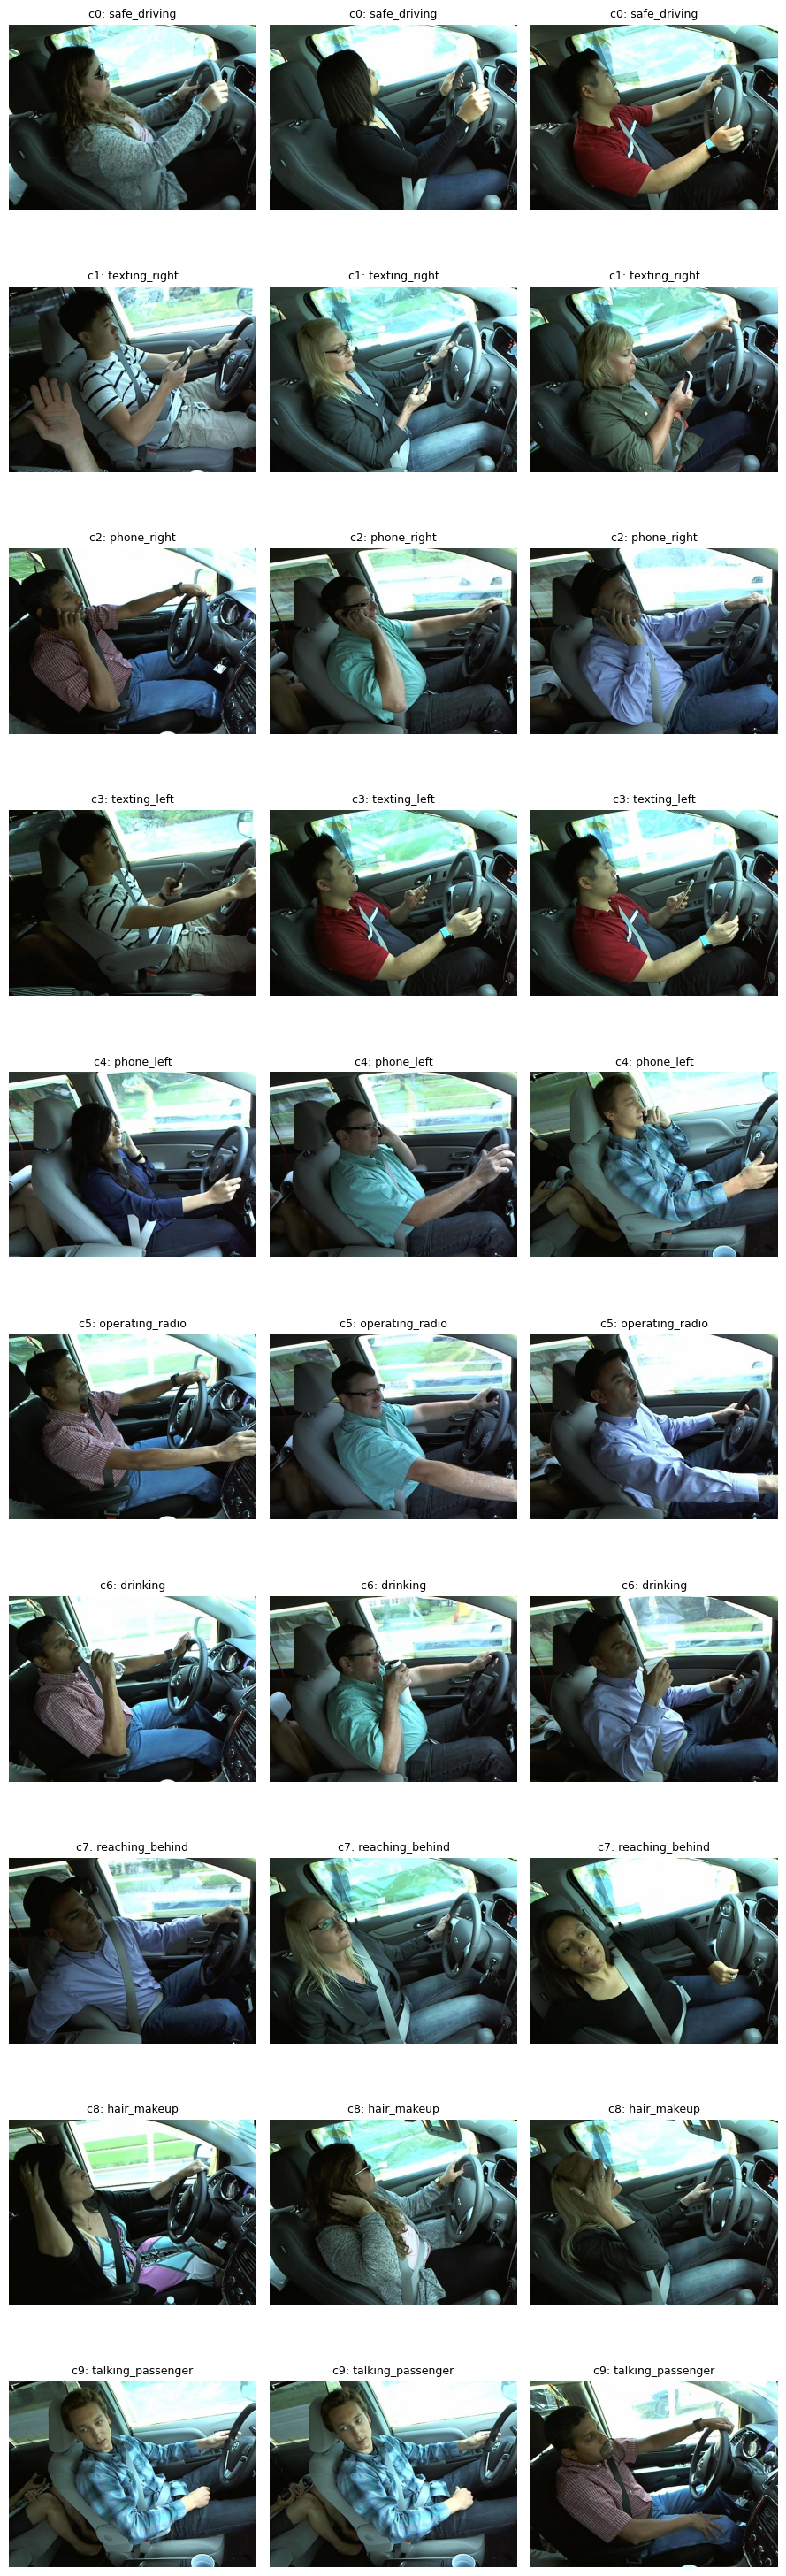

In [5]:
#verify
import matplotlib.pyplot as plt
from PIL import Image

train_dir = next(sf.rglob("train"))
fig, axes = plt.subplots(10, 3, figsize=(9, 30))
for i, (code, name) in enumerate(CLASS_NAMES.items()):
    rows = df[df["classname"] == code].sample(3, random_state=0)
    for j, (_, r) in enumerate(rows.iterrows()):
        axes[i, j].imshow(Image.open(train_dir / code / r["img"]))
        axes[i, j].set_title(f"{code}: {name}", fontsize=9)
        axes[i, j].axis("off")
plt.tight_layout()
plt.show()

In [6]:
df.head()

,subject,classname,img,label
0,p002,c0,img_44733.jpg,safe_driving
1,p002,c0,img_72999.jpg,safe_driving
2,p002,c0,img_25094.jpg,safe_driving
3,p002,c0,img_69092.jpg,safe_driving
4,p002,c0,img_92629.jpg,safe_driving


In [7]:
per_subject=df.groupby("subject").size().sort_values()

In [8]:
per_subject

subject
p072     346
p042     591
p041     605
p039     651
p045     724
p002     725
p052     740
p050     790
p056     794
p061     809
p075     814
p064     820
p081     823
p012     823
p047     835
p035     848
p015     875
p014     876
p051     920
p049    1011
p066    1034
p016    1078
p026    1196
p024    1226
p022    1233
p021    1237
dtype: int64

In [9]:
from PIL import Image

sizes, bad = Counter(), []
for r in df.itertuples():
    path = train_dir / r.classname / r.img
    try:
        with Image.open(path) as im:
            sizes[im.size] += 1
    except Exception as e:
        bad.append((str(path), repr(e)))

print(sizes.most_common(5))
print(len(bad), "unreadable files")
print(bad[:5])

[((640, 480), 22424)]
0 unreadable files
[]


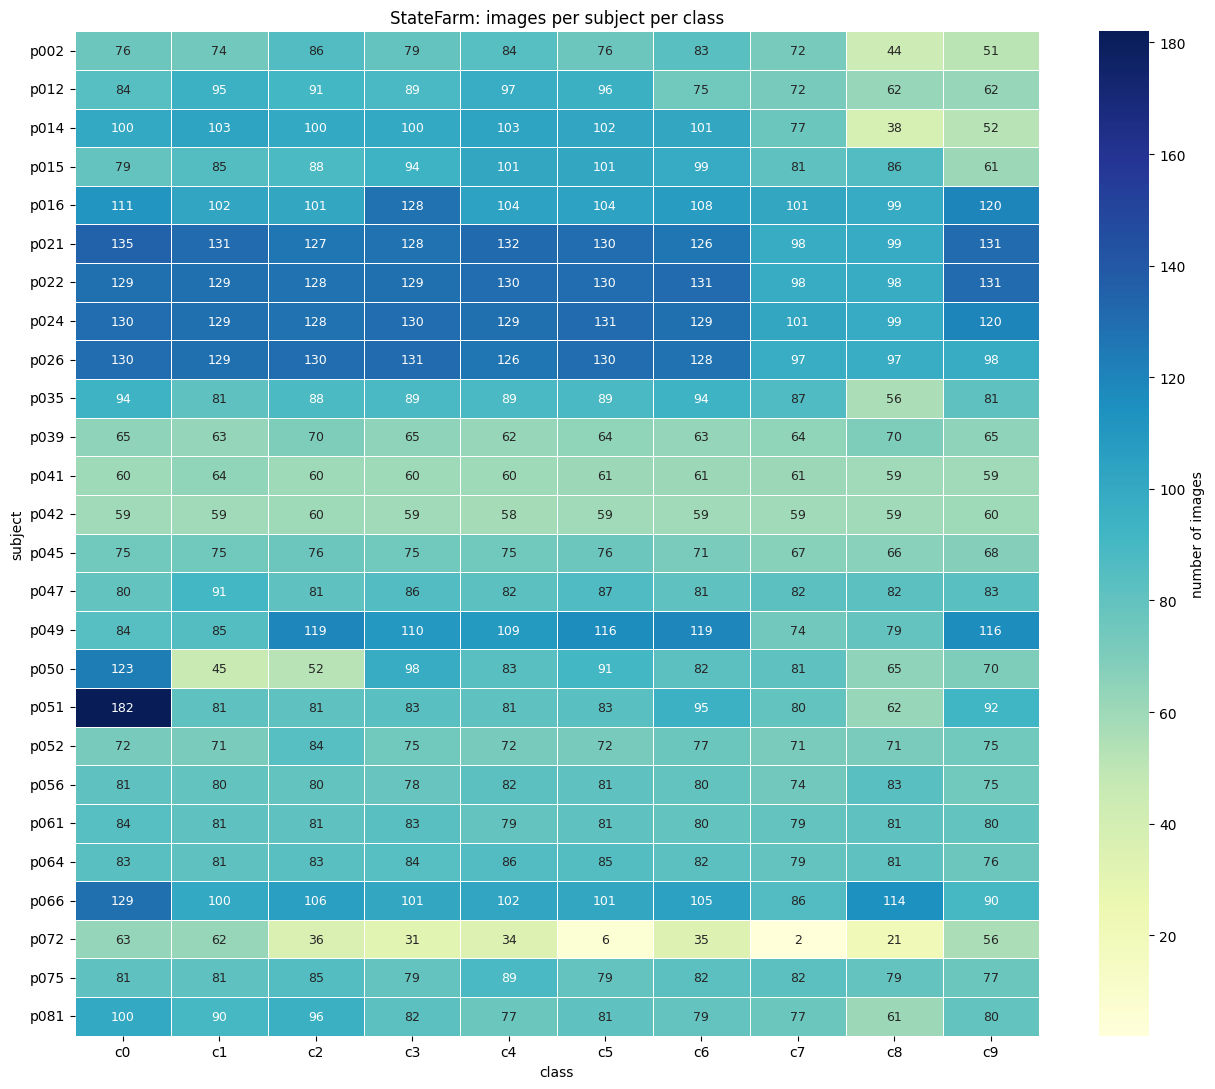

In [10]:
table=pd.crosstab(df['subject'],df['classname'])
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(
    table,
    annot=True, fmt="d",                 # print the count in each cell
    cmap="YlGnBu",                       # light = few, dark = many
    vmin=table.values.min(),             # stretch colors over the real range
    vmax=table.values.max(),
    linewidths=0.5, linecolor="white",   # thin gaps so cells are easy to separate
    cbar_kws={"label": "number of images"},
    annot_kws={"size": 9},
    ax=ax,
)
ax.set_xlabel("class")
ax.set_ylabel("subject")
ax.set_title("StateFarm: images per subject per class")
plt.tight_layout()
plt.show()

In [11]:
sparse = table.stack()
print(sparse[sparse < 30].sort_values())

subject  classname
p072     c7            2
         c5            6
         c8           21
dtype: int64


In [12]:
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
train_idx, val_idx = next(sgkf.split(df, y=df["classname"], groups=df["subject"]))

In [13]:
print(df.iloc[val_idx]["classname"].value_counts().sort_index())
print(df.iloc[val_idx]["subject"].nunique(), "val subjects")

classname
c0    576
c1    455
c2    462
c3    462
c4    470
c5    462
c6    477
c7    426
c8    377
c9    461
Name: count, dtype: int64
5 val subjects


## 3. NTHU-DDD (drowsiness)

### 3.1 Build the master table
This copy is 18,000 JPG frames in two folders (`drowsy`, `notdrowsy`), so the label comes from the folder name. One row per image: `path`, `label`.

In [14]:
nthu = root / "drowsiness" / "nthu_ddd"   # adjust to your path

exts = {".jpg", ".jpeg", ".png"}
rows = []
for f in nthu.rglob("*"):
    if f.is_file() and f.suffix.lower() in exts:
        rows.append({"path": f, "label": f.parent.name})   # "drowsy" / "notdrowsy"
df = pd.DataFrame(rows)

print(df.shape)
print(df["label"].value_counts())
print(df["path"].iloc[:5].map(lambda p: p.name).tolist())   # look at the filenames              # overall

(18000, 2)
label
drowsy       9000
notdrowsy    9000
Name: count, dtype: int64
['001_glasses_sleepyCombination_1003_drowsy.jpg', '001_glasses_sleepyCombination_1005_drowsy.jpg', '001_glasses_sleepyCombination_1012_drowsy.jpg', '001_glasses_sleepyCombination_1013_drowsy.jpg', '001_glasses_sleepyCombination_1019_drowsy.jpg']


### 3.2 Parse filenames
Filenames look like `001_glasses_sleepyCombination_1003_drowsy.jpg`. The regex extracts `subject`, `scenario`, `video`, `frame`. Check: the folder label must equal the label in the filename.

In [15]:
parts = df["path"].map(lambda p: p.stem).str.extract(
    r"^(?P<subject>\d+)_(?P<scenario>[a-zA-Z]+)_(?P<video>[a-zA-Z]+)_(?P<frame>\d+)_(?P<name_label>\w+)$"
)
df = pd.concat([df, parts], axis=1)

print(df[["subject", "scenario", "video"]].isna().sum())   # did the regex match everything?
print(df["subject"].nunique(), "subjects")
print(df["subject"].value_counts().sort_index())
print(pd.crosstab(df["subject"], df["label"]))
print((df["label"] == df["name_label"]).all())             # folder label vs filename label

subject     0
scenario    0
video       0
dtype: int64
4 subjects
subject
001    5213
002    4992
005    5953
006    1842
Name: count, dtype: int64
label    drowsy  notdrowsy
subject                   
001        2466       2747
002        2550       2442
005        3284       2669
006         700       1142
True


**Findings**
- Regex matched every file (0 missing).
- 4 subjects only: 001 (5,213 frames), 002 (4,992), 005 (5,953), 006 (1,842), counted before cleaning.
- Folder label equals filename label for all rows.

**Findings**
- Regex matched every file (0 missing).
- 4 subjects only: 001 (5,213 frames), 002 (4,992), 005 (5,953), 006 (1,842), counted before cleaning.
- Folder label equals filename label for all rows.

**Findings**
- Only 2 scenarios exist: `glasses` and `noglasses`. No night, no sunglasses.
- 4 video types: `nonsleepyCombination`, `sleepyCombination`, `slowBlinkWithNodding`, `yawning`. 27 clips in total.
- Subject 006 is incomplete: glasses only, no `yawning` clip, and a short `slowBlinkWithNodding` (280 frames).

In [16]:
print(pd.crosstab(df["subject"], df["scenario"]))
print(pd.crosstab([df["subject"], df["scenario"]], df["label"]))
print(df.groupby(["subject", "scenario", "video"]).size())

scenario  glasses  noglasses
subject                     
001          2737       2476
002          2603       2389
005          2844       3109
006          1842          0
label              drowsy  notdrowsy
subject scenario                    
001     glasses      1159       1578
        noglasses    1307       1169
002     glasses      1362       1241
        noglasses    1188       1201
005     glasses      1616       1228
        noglasses    1668       1441
006     glasses       700       1142
subject  scenario   video               
001      glasses    nonsleepyCombination    958
                    sleepyCombination       728
                    slowBlinkWithNodding    541
                    yawning                 510
         noglasses  nonsleepyCombination    819
                    sleepyCombination       686
                    slowBlinkWithNodding    473
                    yawning                 498
002      glasses    nonsleepyCombination    842
                    

In [17]:
df.head()

,path,label,subject,scenario,video,frame,name_label
0,D:\driver_monitoring_system\datasets\raw\drows...,drowsy,001,glasses,sleepyCombination,1003,drowsy
1,D:\driver_monitoring_system\datasets\raw\drows...,drowsy,001,glasses,sleepyCombination,1005,drowsy
2,D:\driver_monitoring_system\datasets\raw\drows...,drowsy,001,glasses,sleepyCombination,1012,drowsy
3,D:\driver_monitoring_system\datasets\raw\drows...,drowsy,001,glasses,sleepyCombination,1013,drowsy
4,D:\driver_monitoring_system\datasets\raw\drows...,drowsy,001,glasses,sleepyCombination,1019,drowsy


### 3.4 Label vs video type (shortcut check)
If the video type alone predicts the label, a model can score well without detecting drowsiness.

In [18]:
print(pd.crosstab(df["video"], df["label"]))
print(pd.crosstab(df["video"], df["label"], normalize="index").round(2))   # row percentages

label                 drowsy  notdrowsy
video                                  
nonsleepyCombination      24       6105
sleepyCombination       4324        693
slowBlinkWithNodding    2344       1103
yawning                 2308       1099
label                 drowsy  notdrowsy
video                                  
nonsleepyCombination    0.00       1.00
sleepyCombination       0.86       0.14
slowBlinkWithNodding    0.68       0.32
yawning                 0.68       0.32


**Findings**
| video | drowsy | notdrowsy |
|---|---|---|
| nonsleepyCombination | 24 | 6105 |
| sleepyCombination | 4324 | 693 |
| slowBlinkWithNodding | 2344 | 1103 |
| yawning | 2308 | 1099 |

- Predicting the majority label per video type gives **~84% frame accuracy**. A model must clearly beat this.
- `yawning` and `slowBlinkWithNodding` are mixed (~68% drowsy), so frame labels there carry real information.

### 3.5 Inspect the 24 drowsy frames in `nonsleepyCombination`
These contradict the video type, so they are suspect.

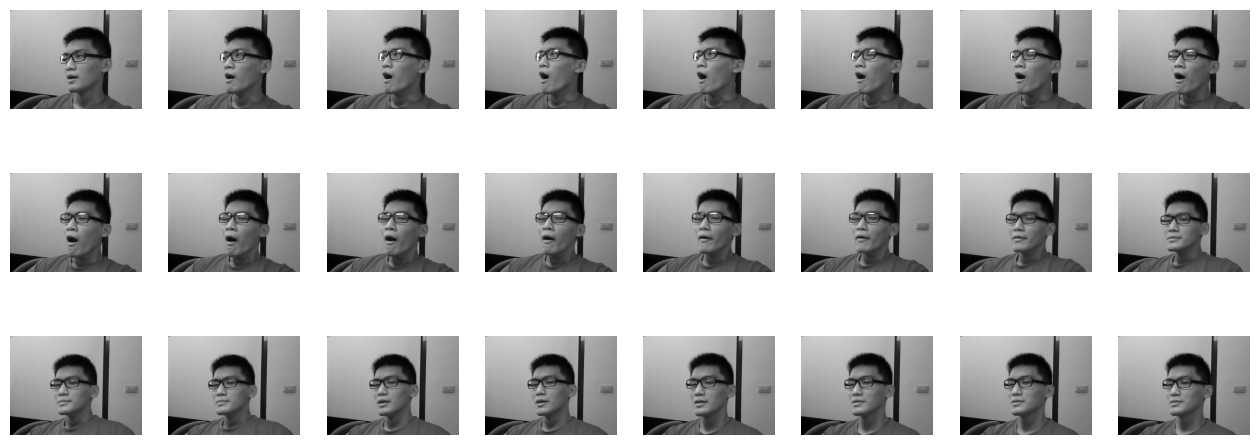

In [19]:
import matplotlib.pyplot as plt
from PIL import Image
odd = df[(df["video"] == "nonsleepyCombination") & (df["label"] == "drowsy")]
fig, axes = plt.subplots(3, 8, figsize=(16, 6))
for ax, p in zip(axes.ravel(), odd["path"]):
    ax.imshow(Image.open(p)); ax.axis("off")
plt.show()

### 3.5 Inspect the 24 drowsy frames in `nonsleepyCombination`
These contradict the video type, so they are suspect.

### 3.6 Frame spacing
Are frames consecutive, and how big are the gaps within a clip?

In [20]:
df["frame"] = df["frame"].astype(int)
df = df.sort_values(["subject", "scenario", "video", "frame"]).reset_index(drop=True)

gap = df.groupby(["subject", "scenario", "video"])["frame"].diff()
print(gap.value_counts().head(10))              # 1 = adjacent frames, larger = skipped frames
print(gap.describe())
print(df.groupby(["subject", "scenario", "video"])["frame"].agg(["min", "max", "count"]))

frame
1.0     4899
2.0     3521
3.0     2586
4.0     1901
5.0     1361
6.0     1033
7.0      733
8.0      539
9.0      369
10.0     273
Name: count, dtype: int64
count    17973.000000
mean         3.692650
std          3.185072
min          1.000000
25%          1.000000
50%          3.000000
75%          5.000000
max         32.000000
Name: frame, dtype: float64
                                        min   max  count
subject scenario  video                                 
001     glasses   nonsleepyCombination    0  3327    958
                  sleepyCombination       3  2746    728
                  slowBlinkWithNodding    2  1920    541
                  yawning                 0  1849    510
        noglasses nonsleepyCombination    2  2731    819
                  sleepyCombination       0  2709    686
                  slowBlinkWithNodding    0  1851    473
                  yawning                 2  1871    498
002     glasses   nonsleepyCombination    5  2932    842
       

**Findings**
- Clips span their full timeline, but only **~28% of frames were kept**, at irregular gaps (median 3, mean 3.7, max 32 frame numbers).
- Neighbouring frames are near-duplicates, so splits must be by subject, never by random frame.
- Time must be measured by `frame` number, not row count.


### 3.7 Cleaning
Drop the 24 suspect frames from 3.5.

In [21]:
df=df.drop(odd.index)

### 3.8 Image integrity
Can every file be opened, and what are the sizes and channel modes?

In [22]:
from PIL import Image
from collections import Counter

sizes, modes, bad = Counter(), Counter(), []
for p in df["path"]:
    try:
        with Image.open(p) as im:
            im.verify()                      # catches truncated or corrupt files without full decode
        with Image.open(p) as im:            # reopen: verify() leaves the file unusable
            sizes[im.size] += 1
            modes[im.mode] += 1
    except Exception as e:
        bad.append((str(p), repr(e)))

print("sizes:", sizes.most_common(5))
print("modes:", modes)                       # "L" = grayscale, "RGB" = colour
print(len(bad), "unreadable files")
print(bad[:5])

sizes: [((640, 480), 17976)]
modes: Counter({'RGB': 17976})
0 unreadable files
[]


### 3.8 Image integrity
Can every file be opened, and what are the sizes and channel modes?

### 3.9 Visual check across classes
Two random frames per (video, label) pair.

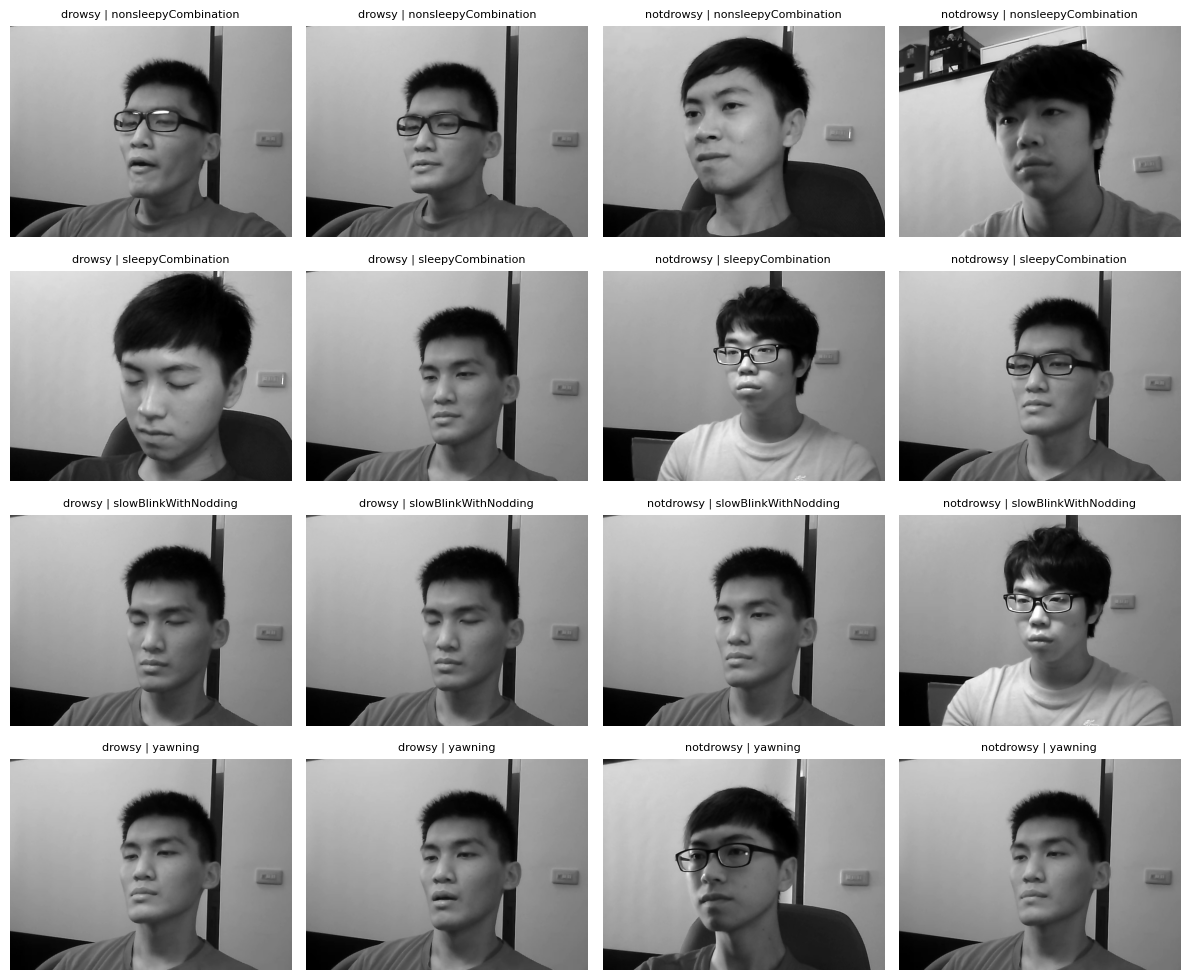

In [23]:
fig, axes = plt.subplots(4, 4, figsize=(12, 10))
sample = df.groupby(["video", "label"]).sample(2, random_state=0, replace=True)
for ax, (_, r) in zip(axes.ravel(), sample.iterrows()):
    ax.imshow(Image.open(r["path"]).convert("RGB"))
    ax.set_title(f"{r['label']} | {r['video']}", fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()

**Findings**
- Labels look plausible: closed eyes in drowsy `sleepyCombination` and `slowBlinkWithNodding`.
- Frames near event boundaries (slightly open mouth, half-closed eyes) look close to the other class, so single-frame labels are noisy there.
- Camera framing, face size and background differ between subjects.

In [24]:
%pip install mediapipe

Note: you may need to restart the kernel to use updated packages.


In [25]:
sizes, modes = Counter(), Counter()
for p in df["path"]:
    with Image.open(p) as im:
        sizes[im.size] += 1
        modes[im.mode] += 1
print("sizes:", sizes.most_common(5))
print("modes:", modes)

sizes: [((640, 480), 17976)]
modes: Counter({'RGB': 17976})


### 3.10 Windows
Plan from the blueprint: 10 s windows, 5 s stride, using `frame` number as the clock. A window's label is drowsy if more than 50% of its kept frames are drowsy.

**Assumption:** `FPS = 30` is not verified. Confirm it from the dataset docs or the source clips.

In [26]:
FPS = 30            # ASSUMPTION: unverified, confirm from the dataset docs or the source clips
WIN, STEP = 10 * FPS, 5 * FPS      # 300 and 150 frame numbers

In [27]:
rows = []
for (subj, scen, vid), g in df.groupby(["subject", "scenario", "video"]):
    f = g["frame"].to_numpy()
    y = (g["label"] == "drowsy").to_numpy()
    for start in range(f.min(), f.max() - WIN + 2, STEP):
        m = (f >= start) & (f < start + WIN)
        if m.sum() > 0:
            rows.append({"subject": subj, "scenario": scen, "video": vid,
                         "start": start, "n": int(m.sum()),
                         "drowsy_frac": y[m].mean()})
wins = pd.DataFrame(rows)
wins["label"] = (wins["drowsy_frac"] > 0.5).astype(int)    # majority rule; note this choice

print(len(wins), "windows")
print(wins["n"].describe())                                  # frames per window
print(wins["label"].value_counts(normalize=True))
print(pd.crosstab(wins["video"], wins["label"]))
print(pd.crosstab(wins["subject"], wins["label"]))
print(wins["drowsy_frac"].round(1).value_counts().sort_index())   # how many windows are mixed

403 windows
count    403.000000
mean      80.846154
std        9.952432
min       48.000000
25%       74.000000
50%       81.000000
75%       88.000000
max      105.000000
Name: n, dtype: float64
label
1    0.550868
0    0.449132
Name: proportion, dtype: float64
label                   0    1
video                         
nonsleepyCombination  129    0
sleepyCombination      12  111
slowBlinkWithNodding   19   58
yawning                21   53
label     0   1
subject        
001      57  59
002      48  64
005      54  81
006      22  18
drowsy_frac
0.0    146
0.1      5
0.2      6
0.3     10
0.4      6
0.5     14
0.6     10
0.7     10
0.8     11
0.9      6
1.0    179
Name: count, dtype: int64


**Findings**
- 403 windows, ~81 frames each (min 48, max 105). No sparse windows.
- 55% drowsy. Per subject: 116 / 112 / 135 / 40 windows (001 / 002 / 005 / 006).
- 81% of windows are pure (146 all-alert + 179 all-drowsy). About 78 are mixed, 14 of them exactly 0.5 (ties go to not drowsy).
- Shortcut baseline at window level: **~87%** from video type alone.
- The real test is drowsy vs alert *inside* the three drowsy-type clips: 274 windows, 222 drowsy, so "always drowsy" already scores 81%.

### 3.11 Save
Index and windows are saved as CSV (parquet failed with this pandas/pyarrow version pair). When loading, convert `path` back with `Path`.

In [34]:
df.to_csv("nthu_index.csv", index=False)
wins.to_csv("nthu_windows.csv", index=False)

## Summary and decisions

**Data limits**
- 4 subjects, daytime only, glasses/no glasses, acted drowsiness.
- Subject 006 is incomplete.
- Frames are subsampled (~28%) and near-duplicates.

**Evaluation plan**
- Leave-one-subject-out, reported per subject, plus a score on the drowsy-type-clips subset.
- Compare against the video-type baseline (~84% frame, ~87% window).
- Describe results as "4 subjects, daytime, acted". Test on YawDD as an external check.

**Open items**
- FPS unverified (assumed 30).
- MediaPipe detection rate untested, to be checked first in notebook 02.

**Next:** `02_drowsiness_feature_extraction`.